# Figure 2: Age structure of operating generation capacity

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lifelines import KaplanMeierFitter
from matplotlib.gridspec import GridSpec

In [5]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset",
)

In [6]:
# ---
# Filter data
# ---

# Remove assets with non-positive lifespans.
df = df[
    df["Lifespan"] > 0
]

# Retain operational assets only.
df = df[
    df["Event"].isin([0])
]

df

,Country,Project Name,Capacity (MW),Technology,Status,Start Year,Retired Year,Lifespan,Event,Unnamed: 9
0,Brazil,3 Tentos Ijuí power station,5.5,Bioenergy,OP,2022.0,NaN,3.0,0.0,NaN
1,Finland,Äänekoski Bioproduct Mill power station,260.0,Bioenergy,OP,2017.0,NaN,8.0,0.0,NaN
2,Finland,Äänekoski power station,35.0,Bioenergy,OP,2002.0,NaN,23.0,0.0,NaN
3,India,Abohar Biomass power station,8.0,Bioenergy,OP,2011.0,NaN,14.0,0.0,NaN
4,Sweden,Åbyverket power station,100.0,Bioenergy,OP,1974.0,NaN,51.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...
96689,United States,Zephyr Wind wind farm,1.5,Wind Onshore,OP,2015.0,NaN,10.0,0.0,NaN
96690,United States,Zephyr Wind wind farm,1.5,Wind Onshore,OP,2015.0,NaN,10.0,0.0,NaN
96691,United States,Zephyr Wind wind farm,1.5,Wind Onshore,OP,2015.0,NaN,10.0,0.0,NaN
96692,Uruguay,Rosario Ventus I wind farm,9.0,Wind Onshore,OP,2015.0,NaN,10.0,0.0,NaN


In [7]:
# ---
# Configuration
# ---

technology_col = "Technology"
capacity_col = "Capacity (MW)"
start_year_col = "Start Year"
retirement_col = "Retired Year"

analysis_year = 2025


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
        "Solar Thermal",
    ],
}

In [8]:
# ---
# Style
# ---

FONT_MIN = 10.0
FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TITLE = 10.5
FONT_PANEL = 10.5
FONT_GROUP_HEADER = 11.0
FONT_REFERENCE_LABEL = 10.0
FONT_INFO = 10.0
FONT_AXIS_LABEL = 11.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_MIN,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Palette
# ---

CURVE_COLOUR = "#222222"
REFERENCE_COLOUR = "#3F708F"
GRID_COLOUR = "#BFBFBF"
SECONDARY_TEXT_COLOUR = "#555555"
TEXT_COLOUR = "#222222"
AXIS_COLOUR = "#444444"
GROUP_LINE_COLOUR = "#777777"


In [9]:
# ---
# Prepare active fleet
# ---

df_plot = df.copy()

df_plot[start_year_col] = pd.to_numeric(
    df_plot[start_year_col],
    errors="coerce",
)

df_plot[retirement_col] = pd.to_numeric(
    df_plot[retirement_col],
    errors="coerce",
)

df_plot[capacity_col] = pd.to_numeric(
    df_plot[capacity_col],
    errors="coerce",
)

# Keep plants with no retirement year or retirement after analysis year.
df_active = df_plot[
    df_plot[start_year_col].notna()
    & df_plot[capacity_col].notna()
    & (df_plot[capacity_col] > 0)
    & (
        df_plot[retirement_col].isna()
        | (df_plot[retirement_col] > analysis_year)
    )
].copy()

# Calculate asset age at the analysis year.
df_active["Age"] = (
    analysis_year
    - df_active[start_year_col]
)

df_active = df_active[
    df_active["Age"].notna()
    & (df_active["Age"] >= 0)
].copy()


In [10]:
# ---
# Helper functions
# ---

# Calculate the capacity-weighted age-survival curve.
# S(x) is the share of active capacity with age >= x.
def capacity_weighted_survival_from_ages(
    ages,
    capacities,
):
    ages = np.asarray(
        ages,
        dtype=float,
    )

    capacities = np.asarray(
        capacities,
        dtype=float,
    )

    valid = (
        np.isfinite(ages)
        & np.isfinite(capacities)
        & (capacities > 0)
    )

    ages = ages[valid]
    capacities = capacities[valid]

    if len(ages) == 0:
        return (
            np.array([]),
            np.array([]),
        )

    total_capacity = capacities.sum()

    unique_ages = np.sort(
        np.unique(ages)
    )

    survival = np.array(
        [
            capacities[ages >= age].sum()
            / total_capacity
            for age in unique_ages
        ]
    )

    # Begin at age zero with all capacity.
    times = np.insert(
        unique_ages,
        0,
        0,
    )

    survival = np.insert(
        survival,
        0,
        1.0,
    )

    return times, survival


# Return the first age at which capacity share reaches a given level.
def get_crossing_age(
    times,
    survival,
    level,
):
    crossed = np.where(
        survival <= level
    )[0]

    if len(crossed) == 0:
        return np.nan

    return times[crossed[0]]


# Summarise the age-survival information for one technology.
def summarise_technology(subset):
    if subset.empty:
        return None

    ages = subset["Age"].to_numpy()
    capacities = subset[capacity_col].to_numpy()

    times, survival = capacity_weighted_survival_from_ages(
        ages,
        capacities,
    )

    if len(times) == 0:
        return None

    return {
        "subset": subset,
        "times": times,
        "S": survival,
        "t80": get_crossing_age(
            times,
            survival,
            0.8,
        ),
        "t50": get_crossing_age(
            times,
            survival,
            0.5,
        ),
        "t10": get_crossing_age(
            times,
            survival,
            0.1,
        ),
        "max_age": np.nanmax(ages),
        "n_units": len(subset),
        "total_cap_mw": subset[capacity_col].sum(),
        "total_cap_gw": (
            subset[capacity_col].sum()
            / 1000
        ),
    }


# Order technologies from older to younger using the 50% crossing age.
def order_technologies_by_oldest(
    group_techs,
    tech_info,
):
    available = [
        tech
        for tech in group_techs
        if (
            tech in tech_info
            and tech_info[tech] is not None
        )
    ]

    return sorted(
        available,
        key=lambda tech: (
            (
                tech_info[tech]["t50"]
                if np.isfinite(
                    tech_info[tech]["t50"]
                )
                else tech_info[tech]["max_age"]
            ),
            tech_info[tech]["max_age"],
        ),
        reverse=True,
    )


# Add a group heading and separator line.
def add_group_header(
    ax,
    title,
):
    ax.axis("off")

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [0.0, 1.0],
        [0.15, 0.15],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# Plot one technology panel.
def plot_panel(
    ax,
    tech,
    info,
    panel_label,
):
    subset = info["subset"]
    times = info["times"]
    survival = info["S"]

    # Active-capacity age curve.
    ax.step(
        times,
        survival,
        where="post",
        color=CURVE_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # Add 80%, 50%, and 10% reference levels.
    total_active_cap_gw = info["total_cap_gw"]

    for level in [
        0.8,
        0.5,
        0.1,
    ]:
        crossed = np.where(
            survival <= level
        )[0]

        if len(crossed) == 0:
            continue

        idx = crossed[0]
        t_level = times[idx]

        # Actual active capacity at or above the threshold age.
        cap_older_gw = (
            subset.loc[
                subset["Age"] >= t_level,
                capacity_col,
            ].sum()
            / 1000
        )

        actual_share = (
            cap_older_gw
            / total_active_cap_gw
            if total_active_cap_gw > 0
            else np.nan
        )

        # Give the median reference stronger emphasis.
        is_median = level == 0.5
        line_alpha = 0.95 if is_median else 0.60
        line_width = 1.00 if is_median else 0.80
        text_alpha = 1.00 if is_median else 0.80

        ax.hlines(
            y=level,
            xmin=0,
            xmax=t_level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.vlines(
            x=t_level,
            ymin=0,
            ymax=level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        ax.text(
            t_level + 1.5,
            min(
                level + 0.018,
                0.98,
            ),
            (
                f"{t_level:.0f} y\n"
                f"{cap_older_gw:.1f} GW | "
                f"{actual_share:.0%}"
            ),
            ha="left",
            va="bottom",
            fontsize=FONT_REFERENCE_LABEL,
            fontweight=(
                "bold"
                if is_median
                else "normal"
            ),
            color=REFERENCE_COLOUR,
            alpha=text_alpha,
            linespacing=1.05,
            zorder=5,
        )

    # Technology-level sample and capacity information.
    ax.text(
        0.97,
        0.95,
        (
            f'n = {info["n_units"]:,} | '
            f'{info["total_cap_gw"]:.2f} GW'
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
    )

    # Panel label and technology title.
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes.
    ax.set_xlim(
        0,
        125,
    )

    ax.set_ylim(
        0,
        1.02,
    )

    ax.set_xticks(
        np.arange(
            0,
            126,
            25,
        )
    )

    ax.set_yticks(
        [
            0,
            0.1,
            0.5,
            0.8,
            1.0,
        ]
    )

    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.spines["left"].set_color(AXIS_COLOUR)
    ax.spines["bottom"].set_color(AXIS_COLOUR)

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelbottom=True,
        labelleft=True,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


In [11]:
# ---
# Pre-calculate technology information
# ---

tech_info = {}

all_group_techs = [
    tech
    for group in tech_groups.values()
    for tech in group
]

for tech in all_group_techs:
    subset = df_active[
        df_active[technology_col] == tech
    ].copy()

    tech_info[tech] = summarise_technology(
        subset
    )


# ---
# Order technologies
# ---

ordered_groups = {
    group_name: order_technologies_by_oldest(
        group_techs,
        tech_info,
    )
    for group_name, group_techs in tech_groups.items()
}



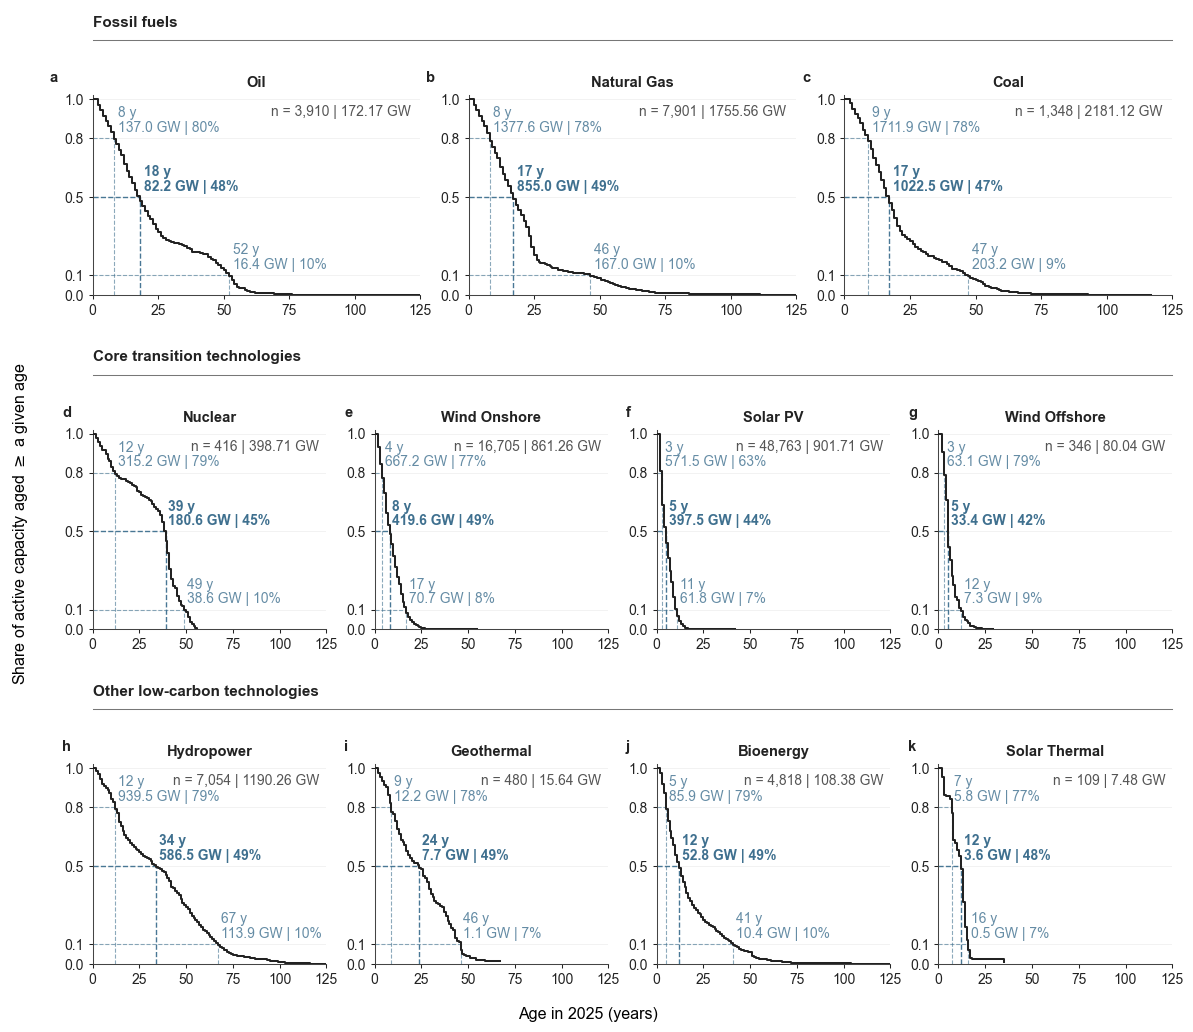

In [12]:
# ---
# Figure
# ---

fig = plt.figure(
    figsize=(11.8, 10.6),
)


# ---
# Grid specification
# ---

gs = GridSpec(
    nrows=6,
    ncols=12,
    figure=fig,
    height_ratios=[
        0.18,
        1.0,
        0.18,
        1.0,
        0.18,
        1.0,
    ],
    hspace=0.42,
    wspace=1.05,
)


# ---
# Group headers
# ---

group_names = list(
    ordered_groups.keys()
)

header_axes = [
    fig.add_subplot(gs[0, :]),
    fig.add_subplot(gs[2, :]),
    fig.add_subplot(gs[4, :]),
]

for ax_header, group_name in zip(
    header_axes,
    group_names,
):
    add_group_header(
        ax_header,
        group_name,
    )


# ---
# Panel positions
# ---

fossil_positions = [
    (1, slice(0, 4)),
    (1, slice(4, 8)),
    (1, slice(8, 12)),
]

transition_positions = [
    (3, slice(0, 3)),
    (3, slice(3, 6)),
    (3, slice(6, 9)),
    (3, slice(9, 12)),
]

other_positions = [
    (5, slice(0, 3)),
    (5, slice(3, 6)),
    (5, slice(6, 9)),
    (5, slice(9, 12)),
]

group_positions = {
    group_names[0]: fossil_positions,
    group_names[1]: transition_positions,
    group_names[2]: other_positions,
}


# ---
# Create panels
# ---

share_ax = None
panel_counter = 0

for group_name in group_names:
    tech_list = ordered_groups[group_name]
    positions = group_positions[group_name]

    for tech, (row_i, col_slice) in zip(
        tech_list,
        positions,
    ):
        if share_ax is None:
            ax = fig.add_subplot(
                gs[
                    row_i,
                    col_slice,
                ]
            )
            share_ax = ax

        else:
            ax = fig.add_subplot(
                gs[
                    row_i,
                    col_slice,
                ],
                sharex=share_ax,
                sharey=share_ax,
            )

        plot_panel(
            ax=ax,
            tech=tech,
            info=tech_info[tech],
            panel_label=chr(
                97 + panel_counter
            ),
        )

        panel_counter += 1


# ---
# Global labels
# ---

fig.supylabel(
    r"Share of active capacity aged $\geq$ a given age",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
)

fig.supxlabel(
    f"Age in {analysis_year} (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.030,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.08,
    right=0.995,
    bottom=0.085,
    top=0.985,
)


# ---
# Save
# ---

plt.savefig(
    "figures/main/figure-2.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-2.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
